In [ ]:
# Cell 1 - Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('../../../results/figures/preprocessing', exist_ok=True)
os.makedirs('../../../results/tables', exist_ok=True)
os.makedirs('../../../data/processed', exist_ok=True)

# Load raw files
appearances       = pd.read_csv('../../../data/raw/appearances.csv')
players           = pd.read_csv('../../../data/raw/players.csv')
player_valuations = pd.read_csv('../../../data/raw/player_valuations.csv')

print("- Raw files loaded!")
print(f"  appearances       : {appearances.shape}")
print(f"  players           : {players.shape}")
print(f"  player_valuations : {player_valuations.shape}")

✅ Raw files loaded!
  appearances       : (1884051, 13)
  players           : (47669, 26)
  player_valuations : (640176, 6)


In [49]:
# Aggregate Appearances
# BEFORE
print("=== BEFORE Aggregation ===")
print(f"appearances: {appearances.shape} — each row = 1 match of 1 player")

# Aggregate by player
player_stats = appearances.groupby(['player_id', 'player_name']).agg(
    total_goals   = ('goals',          'sum'),
    total_assists = ('assists',        'sum'),
    total_yellow  = ('yellow_cards',   'sum'),
    total_red     = ('red_cards',      'sum'),
    total_minutes = ('minutes_played', 'sum'),
    total_games   = ('game_id',        'count')
).reset_index()

player_stats['goal_contribution'] = (
    player_stats['total_goals'] + player_stats['total_assists']
)

# AFTER
print("\n=== AFTER Aggregation ===")
print(f"player_stats: {player_stats.shape} — each row = 1 player")
print(f"\nSample:")
print(player_stats.head(9).to_string())

=== BEFORE Aggregation ===
appearances: (1884051, 13) — each row = 1 match of 1 player

=== AFTER Aggregation ===
player_stats: (28712, 9) — each row = 1 player

Sample:
   player_id          player_name  total_goals  total_assists  total_yellow  total_red  total_minutes  total_games  goal_contribution
0         10       Miroslav Klose           48             25            19          0           8808          136                 73
1         26   Roman Weidenfeller            0              0             4          2          13508          152                  0
2         65     Dimitar Berbatov           38             13            11          1           8788          122                 51
3         77                Lúcio            0              0             0          0            307            4                  0
4         80           Tom Starke            0              0             0          0           1080           12                  0
5        109              

In [50]:
# Step 2 - Column Selection
# BEFORE
print(f"players.csv columns ({len(players.columns)}): {players.columns.tolist()}")

# Select only needed columns
players_clean = players[[
    'player_id', 'name', 'position', 'sub_position',
    'date_of_birth', 'country_of_citizenship', 'height_in_cm',
    'foot', 'current_club_name', 'image_url',
    'market_value_in_eur', 'highest_market_value_in_eur',
    'international_caps', 'international_goals'
]].copy()

# AFTER
dropped = [c for c in players.columns if c not in players_clean.columns]
print(f"\n=== AFTER Column Selection ===")
print(f"players_clean columns ({len(players_clean.columns)}): {players_clean.columns.tolist()}")
print(f"\nDropped {len(dropped)} columns:")
for col in dropped:
    missing_pct = players[col].isnull().sum() / len(players) * 100
    print(f"  ❌ {col} ({missing_pct:.1f}% missing)")

players.csv columns (26): ['player_id', 'first_name', 'last_name', 'name', 'last_season', 'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth', 'country_of_citizenship', 'date_of_birth', 'sub_position', 'position', 'foot', 'height_in_cm', 'contract_expiration_date', 'agent_name', 'image_url', 'international_caps', 'international_goals', 'current_national_team_id', 'url', 'current_club_domestic_competition_id', 'current_club_name', 'market_value_in_eur', 'highest_market_value_in_eur']

=== AFTER Column Selection ===
players_clean columns (14): ['player_id', 'name', 'position', 'sub_position', 'date_of_birth', 'country_of_citizenship', 'height_in_cm', 'foot', 'current_club_name', 'image_url', 'market_value_in_eur', 'highest_market_value_in_eur', 'international_caps', 'international_goals']

Dropped 12 columns:
  ❌ first_name (6.5% missing)
  ❌ last_name (0.0% missing)
  ❌ last_season (0.0% missing)
  ❌ current_club_id (0.0% missing)
  ❌ player_code (0.0% missing)
  ❌ cou

In [51]:
# Merge
# Merge player_stats + players_clean
df_merged = player_stats.merge(players_clean, on='player_id', how='inner')

print(f"=== MERGE RESULT ===")
print(f"player_stats : {player_stats.shape}")
print(f"players_clean: {players_clean.shape}")
print(f"df_merged    : {df_merged.shape}")

print(f"\nMissing values after merge:")
missing = df_merged.isnull().sum()
print(missing[missing > 0].to_string())

=== MERGE RESULT ===
player_stats : (28712, 9)
players_clean: (47669, 14)
df_merged    : (28712, 22)

Missing values after merge:
sub_position                      86
date_of_birth                     24
country_of_citizenship           207
height_in_cm                     925
foot                            1266
current_club_name                563
market_value_in_eur              684
highest_market_value_in_eur      684
international_caps             18714
international_goals            18714


In [52]:
invalid_height = ~df_merged['height_in_cm'].between(150, 210)

print("Invalid height rows:")
print(
    df_merged.loc[
        invalid_height,
        ['player_id', 'player_name', 'height_in_cm']
    ].sort_values('height_in_cm')
)

print("Total invalid:", invalid_height.sum())

Invalid height rows:
       player_id        player_name  height_in_cm
27154     965996           Adi Yona          17.0
27518    1021813    Eugene Amankwah          18.0
25160     743556       Connor Allan          19.0
2             65   Dimitar Berbatov           NaN
3             77              Lúcio           NaN
...          ...                ...           ...
28689    1428464   Abdoulaye Camara           NaN
28692    1437503         Ayaz Özcan           NaN
28693    1442626   Kamil Efe Üregen           NaN
28698    1457761  Theodor Lundbergh           NaN
28704    1476385       Sil Blokhuis           NaN

[928 rows x 3 columns]
Total invalid: 928


In [53]:
# ============================================================
# Data Quality Check - Height
# ============================================================

invalid_height = (
    df_merged['height_in_cm'].notna()
    & ~df_merged['height_in_cm'].between(150, 210)
)

print("Invalid non-missing height rows:")

print(
    df_merged.loc[
        invalid_height,
        ['player_id', 'player_name', 'height_in_cm']
    ].sort_values('height_in_cm')
)

print("\nActual invalid heights:", invalid_height.sum())
print(
    "Original missing heights:",
    df_merged['height_in_cm'].isna().sum()
)

Invalid non-missing height rows:
       player_id      player_name  height_in_cm
27154     965996         Adi Yona          17.0
27518    1021813  Eugene Amankwah          18.0
25160     743556     Connor Allan          19.0

Actual invalid heights: 3
Original missing heights: 925


In [54]:
print(
    "Invalid heights remaining:",
    ((df_merged['height_in_cm'] < 140) |
     (df_merged['height_in_cm'] > 220)).sum()
)

Invalid heights remaining: 3


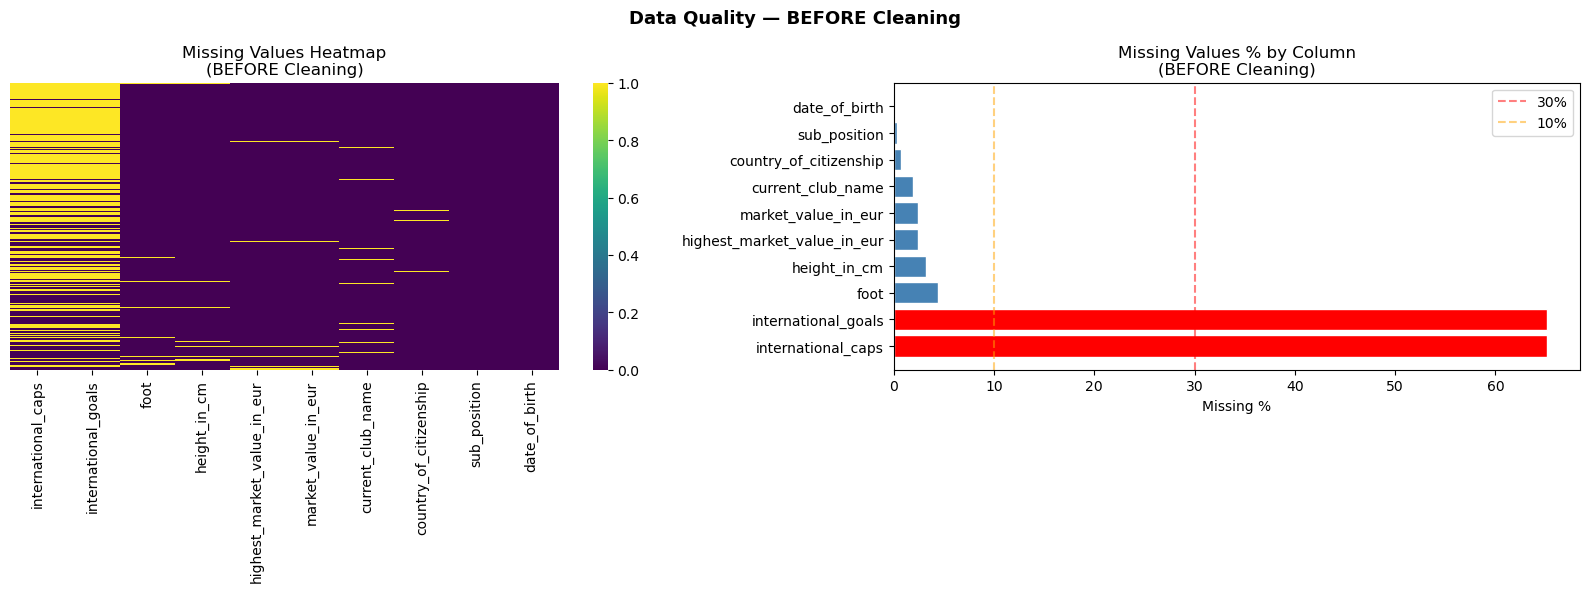

Saved


In [55]:
# Missing Values BEFORE (Chart)
missing_before = pd.DataFrame({
    'count'  : df_merged.isnull().sum(),
    'percent': (df_merged.isnull().sum() / len(df_merged) * 100).round(2)
}).sort_values('percent', ascending=False)

missing_only = missing_before[missing_before['count'] > 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap
sns.heatmap(df_merged[missing_only.index].isnull(),
            yticklabels=False, cbar=True,
            cmap='viridis', ax=axes[0])
axes[0].set_title('Missing Values Heatmap\n(BEFORE Cleaning)')

# Bar chart
colors = ['red' if p > 30 else 'orange' if p > 10 else 'steelblue'
          for p in missing_only['percent']]
axes[1].barh(missing_only.index, missing_only['percent'],
             color=colors, edgecolor='white')
axes[1].set_title('Missing Values % by Column\n(BEFORE Cleaning)')
axes[1].set_xlabel('Missing %')
axes[1].axvline(30, color='red',    linestyle='--', alpha=0.5, label='30%')
axes[1].axvline(10, color='orange', linestyle='--', alpha=0.5, label='10%')
axes[1].legend()

plt.suptitle('Data Quality — BEFORE Cleaning',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/preprocessing/01_missing_before.png', dpi=150)
plt.show()
print("Saved")

In [56]:
# Handle Missing Values
print("=== Handling Missing Values ===\n")

# 1. Drop rows without market value (TARGET)
before = len(df_merged)
df_merged = df_merged.dropna(subset=['market_value_in_eur'])
print(f"Dropped rows without market_value: {before - len(df_merged):,} rows removed")

# 2. Calculate age
df_merged['date_of_birth'] = pd.to_datetime(df_merged['date_of_birth'])
df_merged['age'] = 2024 - df_merged['date_of_birth'].dt.year
print(f"Calculated age from date_of_birth")

# Keep missing height values as NaN.
# Height imputation will be fitted on training data only
# inside the ML Pipeline to avoid data leakage.

df_merged['age'] = df_merged['age'].fillna(
    df_merged['age'].median()
)

print(
    "Missing height values kept as NaN "
    "for training-only median imputation in the ML pipeline"
)

# 4. Fill categorical
df_merged['sub_position']           = df_merged['sub_position'].fillna('Unknown')
df_merged['country_of_citizenship'] = df_merged['country_of_citizenship'].fillna('Unknown')
df_merged['current_club_name']      = df_merged['current_club_name'].fillna('Unknown')
df_merged['foot']                   = df_merged['foot'].fillna('Unknown')
print(f"Filled categorical columns with 'Unknown'")

# 5. Fill international stats with 0
df_merged['international_caps']  = df_merged['international_caps'].fillna(0)
df_merged['international_goals'] = df_merged['international_goals'].fillna(0)
print(f"Filled international_caps/goals with 0 (NaN = never called up)")

print(f"\nMissing values remaining: {df_merged.isnull().sum().sum()}")

=== Handling Missing Values ===

Dropped rows without market_value: 684 rows removed
Calculated age from date_of_birth
Missing height values kept as NaN for training-only median imputation in the ML pipeline
Filled categorical columns with 'Unknown'
Filled international_caps/goals with 0 (NaN = never called up)

Missing values remaining: 810


In [57]:
# ============================================================
# Data Quality Check - Age
# ============================================================

print("=== Age Distribution ===")
print(df_merged['age'].describe())

print("\nPlayers younger than 16:")
print(
    df_merged.loc[
        df_merged['age'] < 16,
        ['player_id', 'player_name', 'age', 'market_value_in_eur']
    ].sort_values('age')
)

print("\nPlayers older than 40:")
print(
    df_merged.loc[
        df_merged['age'] > 40,
        ['player_id', 'player_name', 'age', 'market_value_in_eur']
    ].sort_values('age', ascending=False)
)

print("\nCount age < 16:", (df_merged['age'] < 16).sum())
print("Count age > 40:", (df_merged['age'] > 40).sum())

=== Age Distribution ===
count    28028.000000
mean        29.660839
std          6.865673
min         14.000000
25%         24.000000
50%         29.000000
75%         34.000000
max         54.000000
Name: age, dtype: float64

Players younger than 16:
       player_id             player_name   age  market_value_in_eur
28662    1378338            Linus Güther  14.0            1000000.0
28676    1390964           Eirik Granaas  14.0             400000.0
28315    1169411          Luca Weinhandl  15.0            2000000.0
28405    1187629              Max Dowman  15.0           20000000.0
28461    1223332          Ali Demirbilek  15.0             200000.0
28462    1223408        Samet Akif Duyur  15.0              25000.0
28415    1189915       Mikkel Bro Hansen  15.0             800000.0
28460    1223303             Yakub İlçin  15.0             300000.0
28541    1261862    Tarık Buğra Kalpaklı  15.0             200000.0
28466    1226357             Brian Madjo  15.0           12000000.0

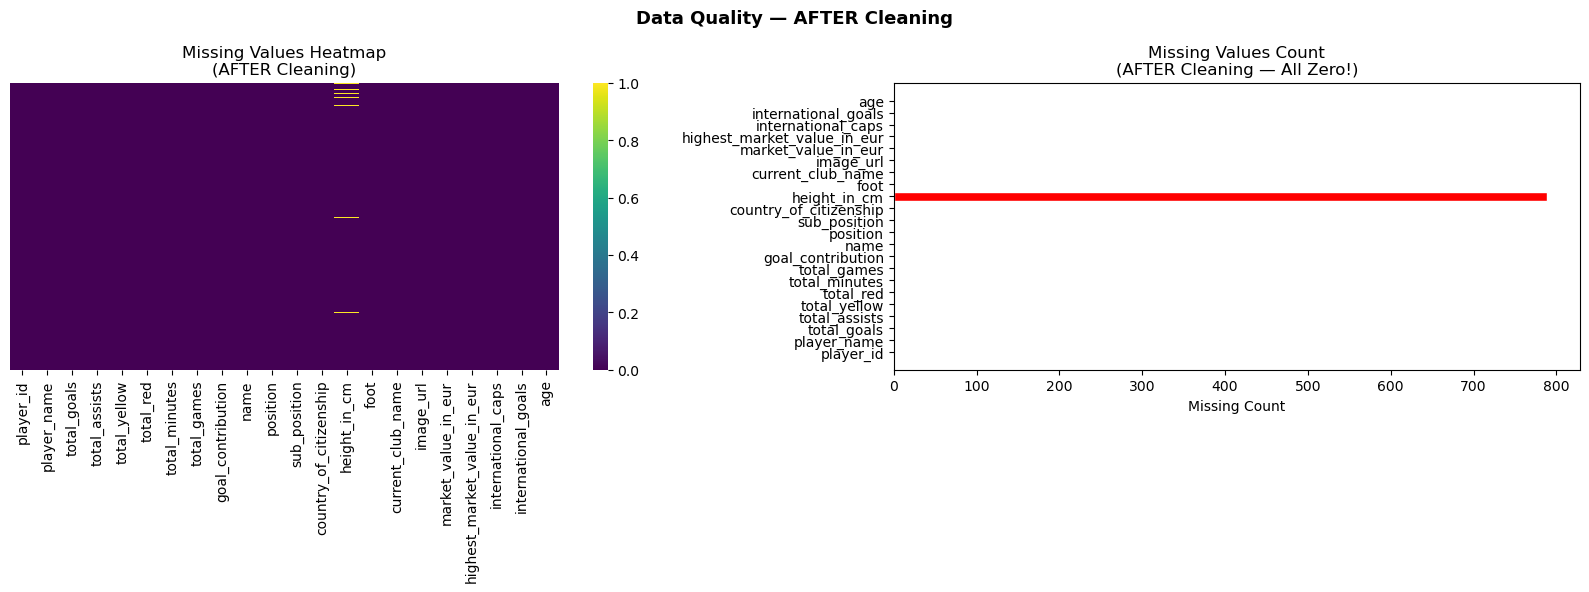

Saved


In [58]:
# Drop date_of_birth trước khi show AFTER chart
df_merged = df_merged.drop(columns=['date_of_birth'], errors='ignore')
# Missing Values AFTER (Chart)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap AFTER
sns.heatmap(df_merged.isnull(),
            yticklabels=False, cbar=True,
            cmap='viridis', ax=axes[0])
axes[0].set_title('Missing Values Heatmap\n(AFTER Cleaning)')

# Bar chart AFTER
missing_after = df_merged.isnull().sum()
colors = ['red' if v > 0 else 'mediumseagreen'
          for v in missing_after.values]
axes[1].barh(missing_after.index, missing_after.values,
             color=colors, edgecolor='white')
axes[1].set_title('Missing Values Count\n(AFTER Cleaning — All Zero!)')
axes[1].set_xlabel('Missing Count')

plt.suptitle('Data Quality — AFTER Cleaning',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/preprocessing/02_missing_after.png', dpi=150)
plt.show()
print("Saved")

In [59]:
# Drop Unnecessary Columns

# BEFORE
print(f"Columns BEFORE drop ({len(df_merged.columns)}): {df_merged.columns.tolist()}")

df_merged = df_merged.drop(columns=[
    'name', 'image_url', 'foot',
    'current_club_name', 'date_of_birth'
], errors='ignore')  # ← thêm errors='ignore'

df_merged = df_merged.reset_index(drop=True)

# AFTER
print(f"\nColumns AFTER drop ({len(df_merged.columns)}): {df_merged.columns.tolist()}")
print(f"\nFinal shape: {df_merged.shape}")

Columns BEFORE drop (22): ['player_id', 'player_name', 'total_goals', 'total_assists', 'total_yellow', 'total_red', 'total_minutes', 'total_games', 'goal_contribution', 'name', 'position', 'sub_position', 'country_of_citizenship', 'height_in_cm', 'foot', 'current_club_name', 'image_url', 'market_value_in_eur', 'highest_market_value_in_eur', 'international_caps', 'international_goals', 'age']

Columns AFTER drop (18): ['player_id', 'player_name', 'total_goals', 'total_assists', 'total_yellow', 'total_red', 'total_minutes', 'total_games', 'goal_contribution', 'position', 'sub_position', 'country_of_citizenship', 'height_in_cm', 'market_value_in_eur', 'highest_market_value_in_eur', 'international_caps', 'international_goals', 'age']

Final shape: (28028, 18)


=== BEFORE Encoding ===
position unique values: ['Attack', 'Goalkeeper', 'Defender', 'Midfield', 'Missing']
sub_position unique values: 14 unique

=== AFTER Encoding ===
position mapping:
  Attack → 0
  Defender → 1
  Goalkeeper → 2
  Midfield → 3
  Missing → 4


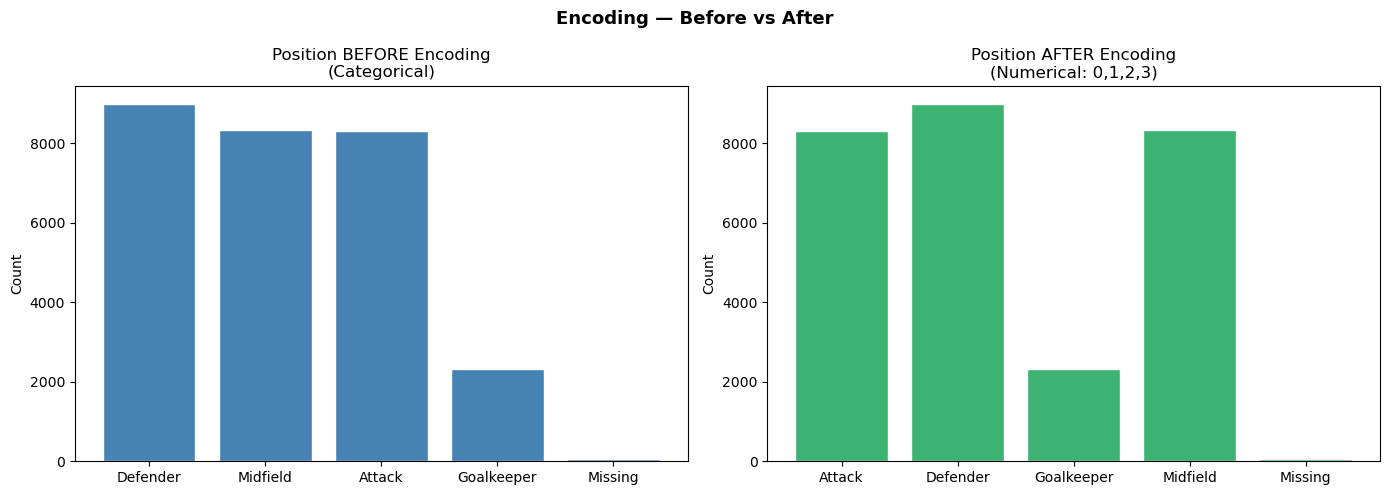

Saved


In [60]:
# Encoding BEFORE/AFTER

from sklearn.preprocessing import LabelEncoder

# BEFORE
print("=== BEFORE Encoding ===")
print(f"position unique values: {df_merged['position'].unique().tolist()}")
print(f"sub_position unique values: {df_merged['sub_position'].nunique()} unique")

# Encode
le_position = LabelEncoder()
le_sub      = LabelEncoder()

df_merged['position_encoded']     = le_position.fit_transform(df_merged['position'])
df_merged['sub_position_encoded'] = le_sub.fit_transform(df_merged['sub_position'])

# AFTER
print("\n=== AFTER Encoding ===")
print("position mapping:")
for i, label in enumerate(le_position.classes_):
    print(f"  {label} → {i}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pos_counts = df_merged['position'].value_counts()
axes[0].bar(pos_counts.index, pos_counts.values,
            color='steelblue', edgecolor='white')
axes[0].set_title('Position BEFORE Encoding\n(Categorical)')
axes[0].set_ylabel('Count')

axes[1].bar(le_position.classes_,
            df_merged['position_encoded'].value_counts().sort_index().values,
            color='mediumseagreen', edgecolor='white')
axes[1].set_title('Position AFTER Encoding\n(Numerical: 0,1,2,3)')
axes[1].set_ylabel('Count')

plt.suptitle('Encoding — Before vs After', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/preprocessing/03_encoding_before_after.png', dpi=150)
plt.show()
print("Saved")

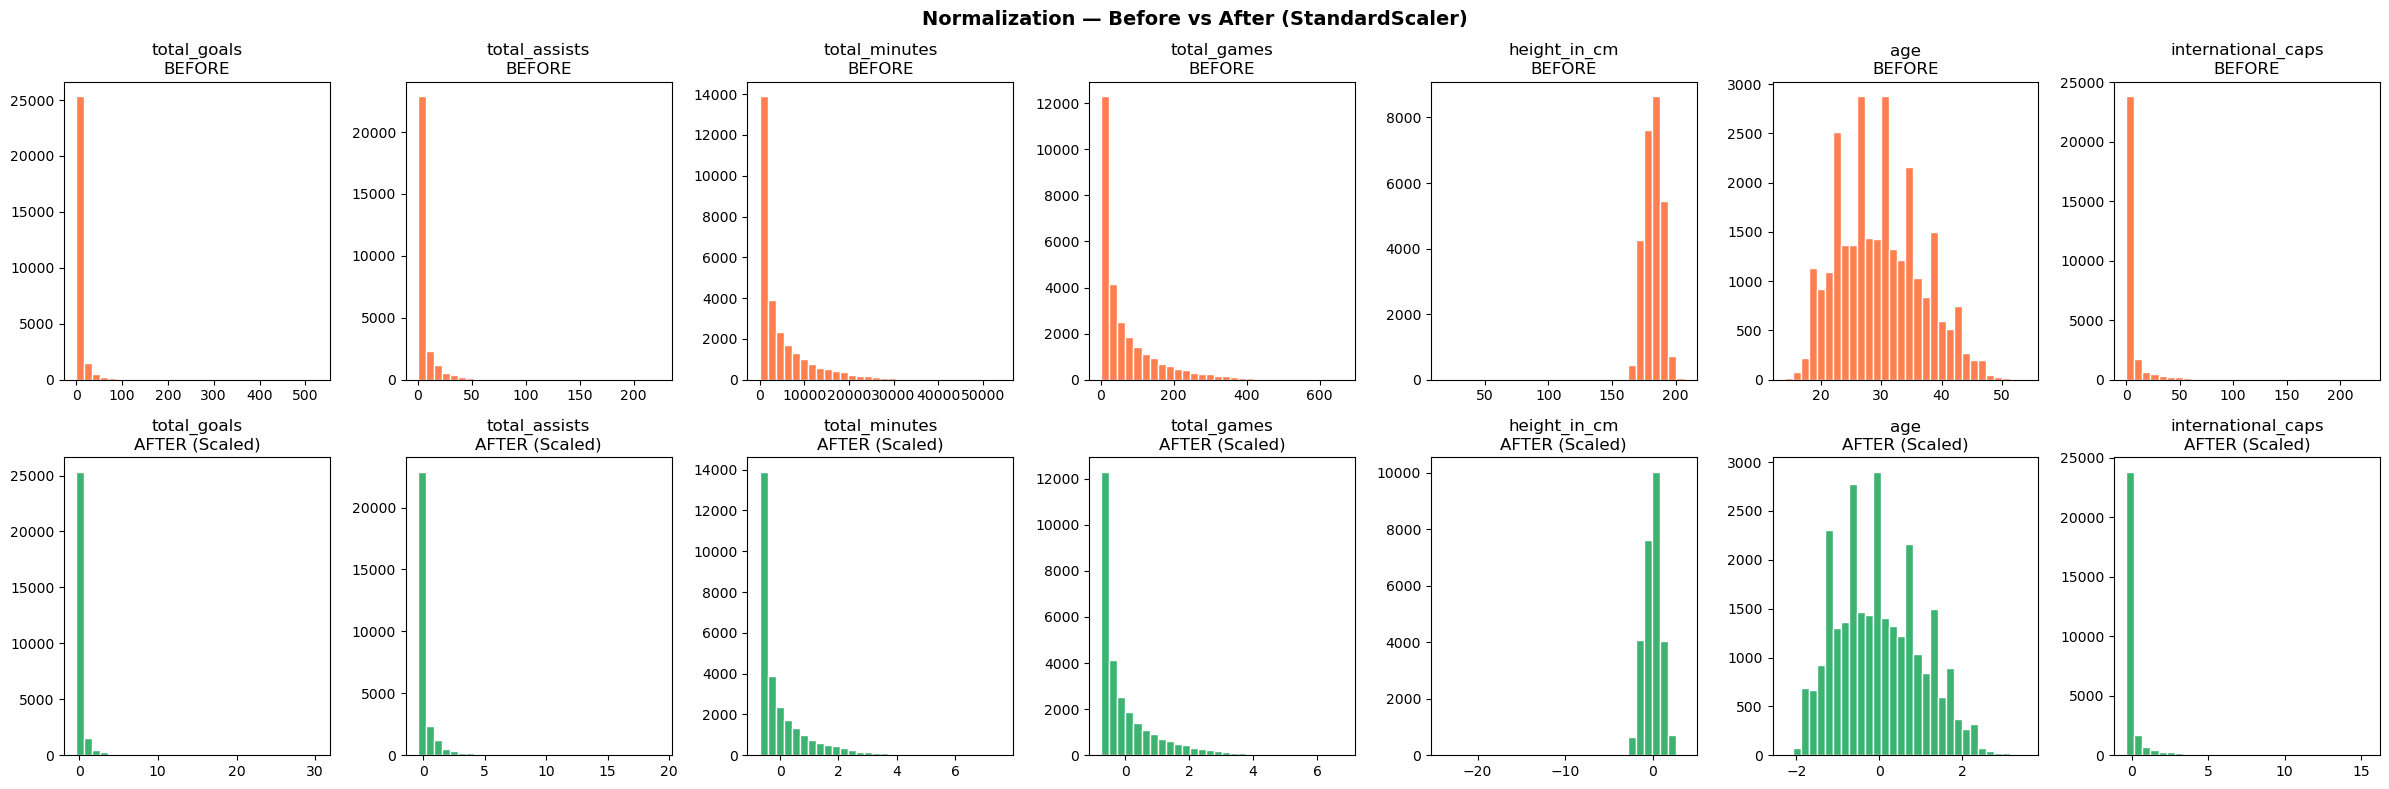

Saved


In [61]:
# NOrmalization BEFORE/AFTER

from sklearn.preprocessing import StandardScaler

numerical_features = ['total_goals', 'total_assists', 'total_minutes',
                      'total_games', 'height_in_cm', 'age',
                      'international_caps']

df_scaled = df_merged[numerical_features].copy()
scaler    = StandardScaler()
df_scaled_values = scaler.fit_transform(df_scaled)
df_scaled = pd.DataFrame(df_scaled_values, columns=numerical_features)

fig, axes = plt.subplots(2, len(numerical_features), figsize=(24, 8))

for i, col in enumerate(numerical_features):
    # BEFORE
    axes[0, i].hist(df_merged[col], bins=30,
                    color='coral', edgecolor='white')
    axes[0, i].set_title(f'{col}\nBEFORE')

    # AFTER
    axes[1, i].hist(df_scaled[col], bins=30,
                    color='mediumseagreen', edgecolor='white')
    axes[1, i].set_title(f'{col}\nAFTER (Scaled)')

plt.suptitle('Normalization — Before vs After (StandardScaler)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/preprocessing/04_normalization_before_after.png', dpi=150)
plt.show()
print("Saved")

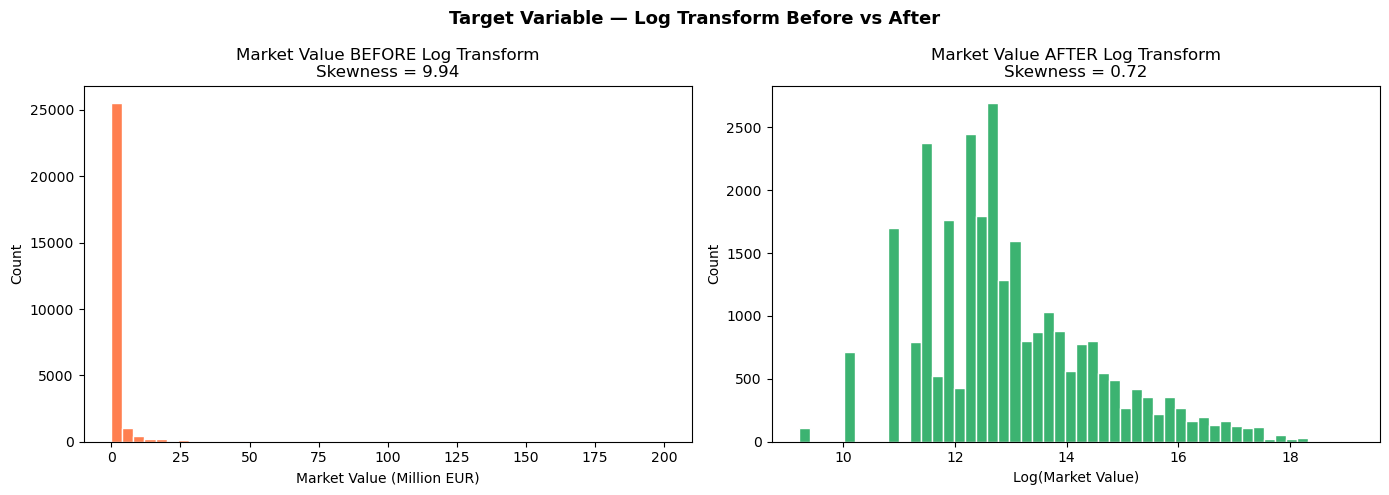

Saved


In [62]:
# Log Transform Target

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# BEFORE
axes[0].hist(df_merged['market_value_in_eur'] / 1_000_000,
             bins=50, color='coral', edgecolor='white')
axes[0].set_title(f'Market Value BEFORE Log Transform\n'
                  f'Skewness = {df_merged["market_value_in_eur"].skew():.2f}')
axes[0].set_xlabel('Market Value (Million EUR)')
axes[0].set_ylabel('Count')

# AFTER
log_mv = np.log1p(df_merged['market_value_in_eur'])
axes[1].hist(log_mv, bins=50,
             color='mediumseagreen', edgecolor='white')
axes[1].set_title(f'Market Value AFTER Log Transform\n'
                  f'Skewness = {log_mv.skew():.2f}')
axes[1].set_xlabel('Log(Market Value)')
axes[1].set_ylabel('Count')

plt.suptitle('Target Variable — Log Transform Before vs After',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../../../results/figures/preprocessing/05_log_transform.png', dpi=150)
plt.show()
print("Saved")

In [63]:
# Feature Summary Table

summary = pd.DataFrame({
    'Column'   : df_merged.columns,
    'Type'     : df_merged.dtypes.values,
    'Nunique'  : df_merged.nunique().values,
    'Missing'  : df_merged.isnull().sum().values,
    'Category' : ['Numerical' if str(t) in ['int64', 'float64']
                  else 'Categorical'
                  for t in df_merged.dtypes.values]
})

print("=== FINAL DATASET SUMMARY ===")
print(f"Shape: {df_merged.shape}")
print(f"Missing: {df_merged.isnull().sum().sum()}")
print(f"\n{summary.to_string(index=False)}")

summary.to_csv('../../../results/tables/feature_summary.csv', index=False)
print("\nSaved feature_summary.csv")

=== FINAL DATASET SUMMARY ===
Shape: (28028, 20)
Missing: 789

                     Column    Type  Nunique  Missing    Category
                  player_id   int64    28028        0   Numerical
                player_name  object    27448        0 Categorical
                total_goals   int64      187        0   Numerical
              total_assists   int64      131        0   Numerical
               total_yellow   int64      128        0   Numerical
                  total_red   int64        9        0   Numerical
              total_minutes   int64    10859        0   Numerical
                total_games   int64      534        0   Numerical
          goal_contribution   int64      256        0   Numerical
                   position  object        5        0 Categorical
               sub_position  object       14        0 Categorical
     country_of_citizenship  object      181        0 Categorical
               height_in_cm float64       53      789   Numerical
        marke

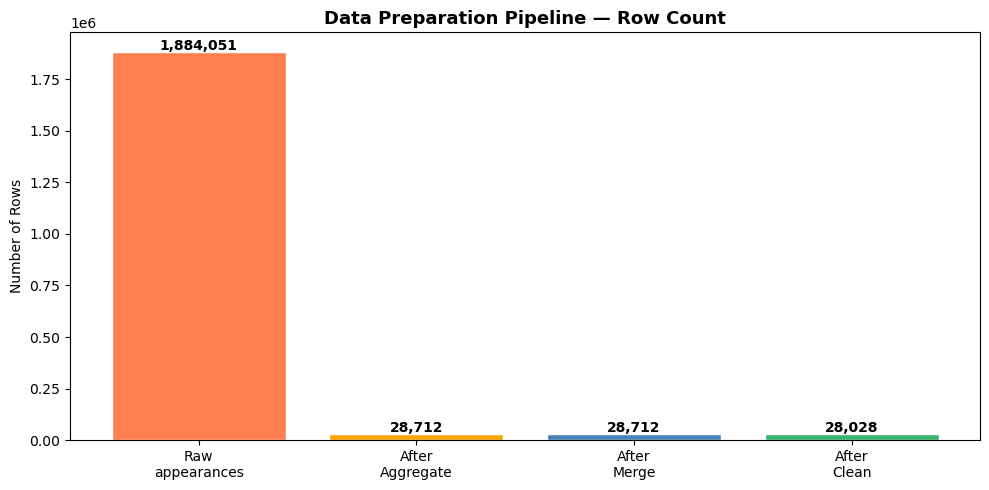

Saved


In [64]:
# Pipeline Summary Chart

steps  = ['Raw\nappearances', 'After\nAggregate',
           'After\nMerge', 'After\nClean']
rows   = [1_884_051, 28_712, 28_712, 28_028]
colors = ['coral', 'orange', 'steelblue', 'mediumseagreen']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(steps, rows, color=colors, edgecolor='white')
ax.set_title('Data Preparation Pipeline — Row Count',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Rows')
for bar, v in zip(bars, rows):
    ax.text(bar.get_x() + bar.get_width()/2,
            v + 10000, f'{v:,}',
            ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('../../../results/figures/preprocessing/06_pipeline_summary.png', dpi=150)
plt.show()
print("Saved")

In [65]:
# ============================================================
# Feature Engineering - Performance Rates
# ============================================================

# Performance per 90 minutes
df_merged['goals_per_90'] = (
    df_merged['total_goals'] /
    df_merged['total_minutes'].replace(0, np.nan)
) * 90

df_merged['assists_per_90'] = (
    df_merged['total_assists'] /
    df_merged['total_minutes'].replace(0, np.nan)
) * 90

df_merged['goal_contribution_per_90'] = (
    df_merged['goal_contribution'] /
    df_merged['total_minutes'].replace(0, np.nan)
) * 90

# Playing-time intensity
df_merged['minutes_per_game'] = (
    df_merged['total_minutes'] /
    df_merged['total_games'].replace(0, np.nan)
)

print(
    df_merged[
        [
            'goals_per_90',
            'assists_per_90',
            'goal_contribution_per_90',
            'minutes_per_game'
        ]
    ].describe()
)

       goals_per_90  assists_per_90  goal_contribution_per_90  \
count  28028.000000    28028.000000              28028.000000   
mean       0.110762        0.087037                  0.197799   
std        0.408738        0.595582                  0.727719   
min        0.000000        0.000000                  0.000000   
25%        0.000000        0.000000                  0.000000   
50%        0.028390        0.028872                  0.092119   
75%        0.142362        0.120202                  0.287674   
max       45.000000       90.000000                 90.000000   

       minutes_per_game  
count      28028.000000  
mean          58.493746  
std           23.957965  
min            1.000000  
25%           43.000000  
50%           62.500000  
75%           77.840489  
max          120.000000  


In [66]:
# ============================================================
# Inspect Extreme Per-90 Values
# ============================================================

rate_cols = [
    'goals_per_90',
    'assists_per_90',
    'goal_contribution_per_90'
]

print("=== Top 15 Extreme Per-90 Records ===")

print(
    df_merged[
        [
            'player_id',
            'player_name',
            'total_games',
            'total_minutes',
            'total_goals',
            'total_assists',
            'goals_per_90',
            'assists_per_90',
            'goal_contribution_per_90'
        ]
    ]
    .sort_values(
        'goal_contribution_per_90',
        ascending=False
    )
    .head(15)
)

print("\n=== Players by total minutes ===")
print("Minutes < 90:", (df_merged['total_minutes'] < 90).sum())
print("Minutes < 180:", (df_merged['total_minutes'] < 180).sum())
print("Minutes < 450:", (df_merged['total_minutes'] < 450).sum())
print("Minutes < 900:", (df_merged['total_minutes'] < 900).sum())

=== Top 15 Extreme Per-90 Records ===
       player_id          player_name  total_games  total_minutes  \
23994     685756  Aleksandr Gapechkin            1              1   
24906     746988        Jesper Uneken            1              2   
12953     237665       André Ferreira            1              3   
22873     622031    Tommaso De Nipoti            2              4   
17665     376784     Patrick Andersen            1              5   
24151     697726       Ivan Zazvonkin            1              6   
14975     291352     Cammy Ballantyne            2              7   
20414     493674           Jack Lahne            1              8   
13398     250007              Clayton            1              9   
18303     398728      Kirill Volchkov            1             13   
21928     569488     Giannis Sardelis            1             13   
18664     411424     Alexandre Llovet            2             16   
26299     923538        Jonas Torsvik            1             16

In [67]:
# ============================================================
# Feature Engineering - Stable Performance Rates
# ============================================================


MIN_MINUTES = 90

sufficient_minutes = df_merged['total_minutes'] >= MIN_MINUTES

df_merged['goals_per_90'] = np.where(
    sufficient_minutes,
    (df_merged['total_goals'] / df_merged['total_minutes']) * 90,
    np.nan
)

df_merged['assists_per_90'] = np.where(
    sufficient_minutes,
    (df_merged['total_assists'] / df_merged['total_minutes']) * 90,
    np.nan
)

df_merged['goal_contribution_per_90'] = np.where(
    sufficient_minutes,
    (df_merged['goal_contribution'] / df_merged['total_minutes']) * 90,
    np.nan
)

df_merged['minutes_per_game'] = (
    df_merged['total_minutes'] /
    df_merged['total_games'].replace(0, np.nan)
)

print(
    "Players below minimum minutes:",
    (~sufficient_minutes).sum()
)

print(
    df_merged[
        [
            'goals_per_90',
            'assists_per_90',
            'goal_contribution_per_90',
            'minutes_per_game'
        ]
    ].describe()
)

Players below minimum minutes: 3132
       goals_per_90  assists_per_90  goal_contribution_per_90  \
count  24896.000000    24896.000000              24896.000000   
mean       0.110717        0.084686                  0.195403   
std        0.163110        0.117952                  0.226086   
min        0.000000        0.000000                  0.000000   
25%        0.000000        0.000000                  0.000000   
50%        0.043449        0.045790                  0.116559   
75%        0.161601        0.131195                  0.313043   
max        2.195122        1.875000                  2.812500   

       minutes_per_game  
count      28028.000000  
mean          58.493746  
std           23.957965  
min            1.000000  
25%           43.000000  
50%           62.500000  
75%           77.840489  
max          120.000000  


In [ ]:
final_columns = [
    'player_id',
    'player_name',
    'total_goals',
    'total_assists',
    'total_yellow',
    'total_red',
    'total_minutes',
    'total_games',
    'goal_contribution',
    'position',
    'sub_position',
    'country_of_citizenship',
    'height_in_cm',
    'market_value_in_eur',
    'highest_market_value_in_eur',
    'international_caps',
    'international_goals',
    'age',
    'position_encoded',
    'sub_position_encoded',
    'goals_per_90',
    'assists_per_90',
    'goal_contribution_per_90',
    'minutes_per_game'
]

df_final = df_merged[final_columns].copy()

In [68]:
# ============================================================
# Save Processed Data
# ============================================================

import os

# Create processed-data directory if needed
os.makedirs('../../../data/processed', exist_ok=True)

# Save final prepared dataset
df_merged.to_csv(
    '../../../data/processed/df_final.csv',
    index=False
)

print("Saved to data/processed/df_final.csv")

print(f"\nFinal dataset shape: {df_merged.shape}")

print("\nMissing values:")
print(
    df_merged[
        [
            'height_in_cm',
            'goals_per_90',
            'assists_per_90',
            'goal_contribution_per_90',
            'minutes_per_game'
        ]
    ].isnull().sum()
)

print("\nEngineered features saved:")
engineered_features = [
    'goals_per_90',
    'assists_per_90',
    'goal_contribution_per_90',
    'minutes_per_game'
]

for feature in engineered_features:
    print(f"  - {feature}")

print("\nColumns:")
print(df_merged.columns.tolist())

Saved to data/processed/df_final.csv

Final dataset shape: (28028, 24)

Missing values:
height_in_cm                 789
goals_per_90                3132
assists_per_90              3132
goal_contribution_per_90    3132
minutes_per_game               0
dtype: int64

Engineered features saved:
  - goals_per_90
  - assists_per_90
  - goal_contribution_per_90
  - minutes_per_game

Columns:
['player_id', 'player_name', 'total_goals', 'total_assists', 'total_yellow', 'total_red', 'total_minutes', 'total_games', 'goal_contribution', 'position', 'sub_position', 'country_of_citizenship', 'height_in_cm', 'market_value_in_eur', 'highest_market_value_in_eur', 'international_caps', 'international_goals', 'age', 'position_encoded', 'sub_position_encoded', 'goals_per_90', 'assists_per_90', 'goal_contribution_per_90', 'minutes_per_game']
